
# Uczenie maszynowe — zajęcia 5
## Reguła Hebba — uczenie przez wzmacnianie współaktywności

**Uniwersytet Warmińsko-Mazurski w Olsztynie**  
**Semestr 5, rok akademicki 2026/2027**  
**Prowadzący: mgr inż. Adrian Albrecht**

---

## Cel zajęć

Na tych zajęciach poznajemy **regułę uczenia Hebba** — jeden z klasycznych mechanizmów modyfikacji wag.

Po zajęciach osoba studiująca powinna umieć:

1. wyjaśnić intuicję reguły Hebba,
2. zapisać podstawową regułę aktualizacji wag,
3. wyjaśnić znaczenie sygnału wejściowego i wyjściowego,
4. zastosować nadzorowaną postać reguły Hebba do prostego problemu binarnego,
5. wyjaśnić rolę kodowania bipolarnego `-1 / 1`,
6. prześledzić zmianę wag krok po kroku,
7. wyjaśnić ograniczenia klasycznej reguły Hebba,
8. samodzielnie zaimplementować prosty klasyfikator `MyHebbClassifier`.

> **Ważne:** gotowa implementacja `MyHebbClassifier` nie znajduje się w notebooku udostępnianym studentom. Implementacja jest pracą własną.



## Plan zajęć — 90 minut

| Czas | Temat |
|---:|---|
| 0–10 min | Intuicja uczenia Hebba |
| 10–25 min | Reguła aktualizacji wag |
| 25–40 min | Kodowanie bipolarne i prosty neuron |
| 40–55 min | AND oraz OR krok po kroku |
| 55–65 min | XOR i ograniczenia reguły |
| 65–75 min | Dane rzeczywiste — dwa gatunki Iris |
| 75–85 min | Demonstracja własnej implementacji |
| 85–90 min | Zadanie samodzielne i podsumowanie |



# 0. Przygotowanie środowiska


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

np.set_printoptions(
    precision=4,
    suppress=True
)

RANDOM_STATE = 42



# 1. Intuicja reguły Hebba

Najczęściej przywoływana intuicja brzmi:

> jeżeli dwa elementy są aktywne jednocześnie, połączenie pomiędzy nimi powinno zostać wzmocnione.

W bardzo uproszczonej postaci zmianę wagi możemy zapisać jako:

$$
\Delta w_i
=
\eta x_i y
$$

gdzie:

- `x_i` — wartość wejścia,
- `y` — aktywność elementu wyjściowego,
- `eta` — współczynnik uczenia,
- `Delta w_i` — zmiana wagi.

Następnie:

$$
w_i^{new}
=
w_i^{old}
+
\Delta w_i
$$



## 1.1. Co oznacza znak iloczynu?

Jeżeli:

$$
x_i y > 0
$$

waga wzrasta.

Jeżeli:

$$
x_i y < 0
$$

waga maleje.

Jeżeli któryś z sygnałów jest równy zero, w najprostszej wersji reguły dana aktualizacja nie zmienia wagi.

To bardzo lokalna reguła: zmiana wagi zależy od sygnałów związanych bezpośrednio z danym połączeniem.


In [2]:

eta = 0.5

examples = [
    (1, 1),
    (1, -1),
    (-1, 1),
    (-1, -1)
]

rows = []

for x_i, y_i in examples:
    delta_w = (
        eta * x_i * y_i
    )

    rows.append({
        "x": x_i,
        "y": y_i,
        "delta_w": delta_w
    })

display(
    pd.DataFrame(rows)
)


,x,y,delta_w
0,1,1,0.5
1,1,-1,-0.5
2,-1,1,-0.5
3,-1,-1,0.5



# 2. Postać wektorowa

Dla obserwacji opisanej wieloma cechami:

$$
\mathbf{x}
=
[x_1,x_2,\dots,x_p]
$$

możemy zapisać zmianę całego wektora wag:

$$
\Delta \mathbf{w}
=
\eta y \mathbf{x}
$$

a aktualizację:

$$
\mathbf{w}
\leftarrow
\mathbf{w}
+
\eta y\mathbf{x}
$$

W wersji nadzorowanej zamiast aktualnej odpowiedzi neuronu możemy wykorzystać wartość docelową:

$$
t \in \{-1,1\}
$$

i wtedy:

$$
\Delta \mathbf{w}
=
\eta t\mathbf{x}
$$

Na tych zajęciach właśnie tę prostą **nadzorowaną postać** wykorzystamy do klasyfikacji binarnej.



# 3. Prosty neuron liniowy

Dla wejścia:

$$
\mathbf{x}
$$

i wag:

$$
\mathbf{w}
$$

obliczamy pobudzenie:

$$
a
=
\mathbf{w}^T\mathbf{x}
+b
$$

Do uzyskania klasy binarnej możemy zastosować funkcję znaku:

$$
\hat{y}
=
\operatorname{sign}(a)
$$

Czyli:

- wynik dodatni → klasa `+1`,
- wynik ujemny → klasa `-1`.

Wyraz wolny `b` możemy traktować jak wagę połączoną ze stałym wejściem:

$$
x_0=1
$$



# 4. Dlaczego kodowanie bipolarne?

W klasycznej demonstracji reguły Hebba wygodne jest kodowanie:

$$
-1
$$

oraz:

$$
1
$$

zamiast:

$$
0
$$

oraz:

$$
1
$$

Dzięki temu znak iloczynu bezpośrednio mówi, czy dwa sygnały są zgodne, czy przeciwne.

Przykładowo:

$$
(+1)(+1)=+1
$$

$$
(-1)(-1)=+1
$$

ale:

$$
(+1)(-1)=-1
$$



# 5. Bramka AND — przygotowanie danych

Zakodujmy wejścia bipolarnie.

Dla AND tylko przypadek:

$$
(1,1)
$$

ma wynik:

$$
1
$$

Pozostałe kombinacje mają wynik:

$$
-1
$$


In [3]:

X_and = np.array([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1]
], dtype=float)

y_and = np.array([
    -1,
    -1,
    -1,
     1
], dtype=float)

display(
    pd.DataFrame({
        "x1": X_and[:, 0],
        "x2": X_and[:, 1],
        "t": y_and
    })
)


,x1,x2,t
0,-1.0,-1.0,-1.0
1,-1.0,1.0,-1.0
2,1.0,-1.0,-1.0
3,1.0,1.0,1.0



# 6. Uczenie AND krok po kroku

Zaczynamy od:

$$
\mathbf{w}
=
[0,0]
$$

oraz:

$$
b=0
$$

Dla każdej próbki wykonujemy:

$$
\mathbf{w}
\leftarrow
\mathbf{w}
+
\eta t\mathbf{x}
$$

oraz:

$$
b
\leftarrow
b+\eta t
$$

Przyjmijmy:

$$
\eta=1
$$

Prześledzimy wszystkie aktualizacje.


In [4]:

w = np.zeros(2)
b = 0.0
eta = 1.0

history = []

for step, (x_i, t_i) in enumerate(
    zip(X_and, y_and),
    start=1
):
    delta_w = eta * t_i * x_i
    delta_b = eta * t_i

    w = w + delta_w
    b = b + delta_b

    history.append({
        "krok": step,
        "x1": x_i[0],
        "x2": x_i[1],
        "t": t_i,
        "delta_w1": delta_w[0],
        "delta_w2": delta_w[1],
        "delta_b": delta_b,
        "w1": w[0],
        "w2": w[1],
        "b": b
    })

display(
    pd.DataFrame(history)
)


,krok,x1,x2,t,delta_w1,delta_w2,delta_b,w1,w2,b
0,1,-1.0,-1.0,-1.0,1.0,1.0,-1.0,1.0,1.0,-1.0
1,2,-1.0,1.0,-1.0,1.0,-1.0,-1.0,2.0,0.0,-2.0
2,3,1.0,-1.0,-1.0,-1.0,1.0,-1.0,1.0,1.0,-3.0
3,4,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,-2.0



## 6.1. Ostateczny neuron

Po przejściu przez wszystkie wzorce otrzymaliśmy konkretne:

- `w1`,
- `w2`,
- `b`.

Sprawdźmy wartość:

$$
a=
\mathbf{w}^T\mathbf{x}+b
$$

dla wszystkich czterech kombinacji.


In [5]:

decision_and = (
    X_and @ w + b
)

pred_and = np.where(
    decision_and >= 0,
    1,
    -1
)

display(
    pd.DataFrame({
        "x1": X_and[:, 0],
        "x2": X_and[:, 1],
        "t": y_and,
        "a": decision_and,
        "predykcja": pred_and
    })
)

print("w =", w)
print("b =", b)


,x1,x2,t,a,predykcja
0,-1.0,-1.0,-1.0,-6.0,-1
1,-1.0,1.0,-1.0,-2.0,-1
2,1.0,-1.0,-1.0,-2.0,-1
3,1.0,1.0,1.0,2.0,1


w = [2. 2.]
b = -2.0



# 7. Granica decyzyjna dla AND

Dla dwóch cech:

$$
w_1x_1+w_2x_2+b=0
$$

stąd:

$$
x_2
=
-\frac{w_1}{w_2}x_1
-
\frac{b}{w_2}
$$


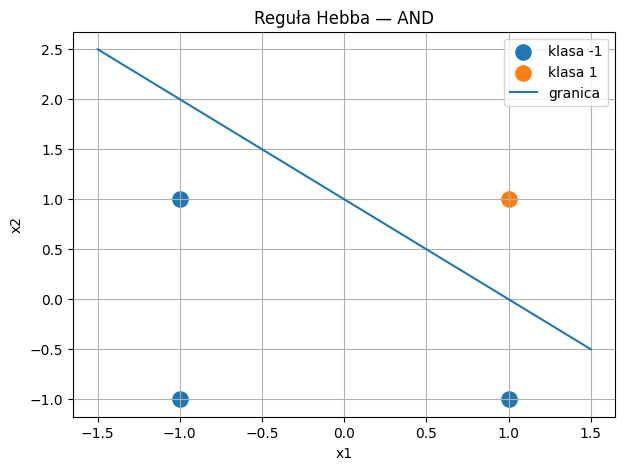

In [6]:

def plot_linear_boundary(
    X,
    y,
    w,
    b,
    title
):
    plt.figure(figsize=(7, 5))

    for class_id in [-1, 1]:
        mask = y == class_id

        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            s=120,
            label=f"klasa {class_id}"
        )

    if abs(w[1]) > 1e-12:
        x_axis = np.linspace(
            X[:, 0].min() - 0.5,
            X[:, 0].max() + 0.5,
            200
        )

        y_axis = (
            -(w[0] / w[1])
            * x_axis
            - b / w[1]
        )

        plt.plot(
            x_axis,
            y_axis,
            label="granica"
        )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


plot_linear_boundary(
    X_and,
    y_and,
    w,
    b,
    "Reguła Hebba — AND"
)



# 8. Bramka OR

Teraz zmieniamy tylko wartości docelowe.

Dla OR wszystkie przypadki poza:

$$
(-1,-1)
$$

należą do klasy:

$$
1
$$

Spróbuj wykonać aktualizacje samodzielnie na kartce przed uruchomieniem kolejnej komórki.


w = [2. 2.]
b = 2.0


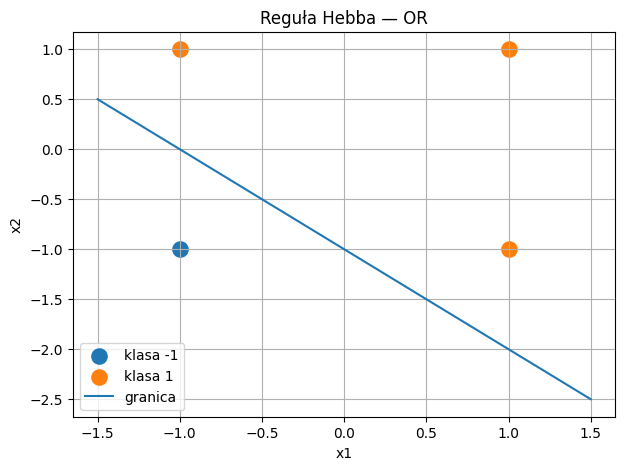

In [7]:

X_or = np.array([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1]
], dtype=float)

y_or = np.array([
    -1,
     1,
     1,
     1
], dtype=float)

w_or = np.zeros(2)
b_or = 0.0

for x_i, t_i in zip(
    X_or,
    y_or
):
    w_or += (
        eta * t_i * x_i
    )

    b_or += (
        eta * t_i
    )

print("w =", w_or)
print("b =", b_or)

plot_linear_boundary(
    X_or,
    y_or,
    w_or,
    b_or,
    "Reguła Hebba — OR"
)



# 9. A co z XOR?

XOR ma strukturę:

| x1 | x2 | t |
|---:|---:|---:|
| -1 | -1 | -1 |
| -1 | 1 | 1 |
| 1 | -1 | 1 |
| 1 | 1 | -1 |

Spróbuj narysować te cztery punkty.

Czy da się przeprowadzić **jedną prostą**, która poprawnie rozdzieli obie klasy?


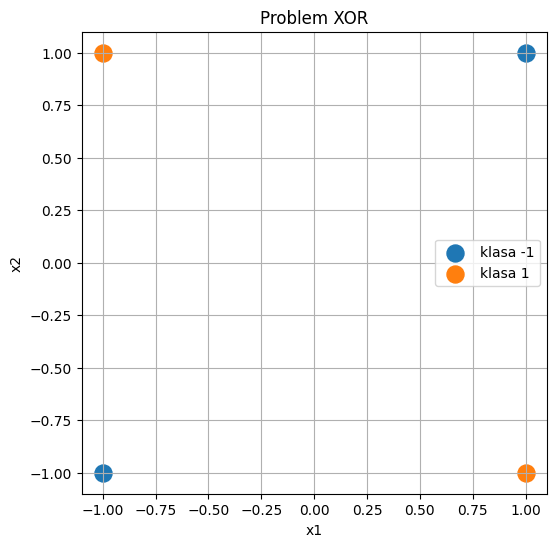

In [8]:

X_xor = np.array([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1]
], dtype=float)

y_xor = np.array([
    -1,
     1,
     1,
    -1
], dtype=float)

plt.figure(figsize=(6, 6))

for class_id in [-1, 1]:
    mask = y_xor == class_id

    plt.scatter(
        X_xor[mask, 0],
        X_xor[mask, 1],
        s=150,
        label=f"klasa {class_id}"
    )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Problem XOR")
plt.legend()
plt.grid()
plt.show()



## 9.1. Ograniczenie modelu liniowego

Neuron o postaci:

$$
\hat{y}
=
\operatorname{sign}
\left(
\mathbf{w}^T\mathbf{x}+b
\right)
$$

tworzy **liniową granicę decyzyjną**.

XOR nie jest liniowo separowalny.

Problem nie polega więc na znalezieniu „lepszego learning rate”.

Ograniczenie wynika z samej postaci modelu.


In [9]:

w_xor = np.zeros(2)
b_xor = 0.0

for x_i, t_i in zip(
    X_xor,
    y_xor
):
    w_xor += (
        eta * t_i * x_i
    )

    b_xor += (
        eta * t_i
    )

decision_xor = (
    X_xor @ w_xor
    + b_xor
)

pred_xor = np.where(
    decision_xor >= 0,
    1,
    -1
)

display(
    pd.DataFrame({
        "x1": X_xor[:, 0],
        "x2": X_xor[:, 1],
        "t": y_xor,
        "a": decision_xor,
        "predykcja": pred_xor
    })
)

print("w =", w_xor)
print("b =", b_xor)


,x1,x2,t,a,predykcja
0,-1.0,-1.0,-1.0,0.0,1
1,-1.0,1.0,1.0,0.0,1
2,1.0,-1.0,1.0,0.0,1
3,1.0,1.0,-1.0,0.0,1


w = [0. 0.]
b = 0.0



# 10. Ważna cecha klasycznej reguły Hebba

Zwróć uwagę na bardzo istotną różnicę względem wielu późniejszych algorytmów uczenia.

W podstawowej nadzorowanej regule Hebba aktualizacja:

$$
\Delta \mathbf{w}
=
\eta t\mathbf{x}
$$

nie zależy od tego, czy model **aktualnie popełnił błąd**.

Waga zmienia się na podstawie wejścia i sygnału docelowego.

Nie mamy tutaj mechanizmu:

> „jeżeli odpowiedź była błędna, popraw wagi”.

To będzie ważne przy porównywaniu Hebba z innymi regułami uczenia.



# 11. Wpływ kolejnych epok

Jeżeli przejdziemy po tych samych danych ponownie, klasyczna reguła Hebba ponownie doda podobne wkłady do wag.

Przy stałej kolejności i tych samych danych wartości wag mogą więc rosnąć wraz z liczbą epok.

Sprawdźmy to dla AND.


In [10]:

epoch_rows = []

for n_epochs in [
    1,
    2,
    5,
    10
]:
    w_temp = np.zeros(2)
    b_temp = 0.0

    for _ in range(n_epochs):
        for x_i, t_i in zip(
            X_and,
            y_and
        ):
            w_temp += (
                eta * t_i * x_i
            )

            b_temp += (
                eta * t_i
            )

    epoch_rows.append({
        "epoki": n_epochs,
        "w1": w_temp[0],
        "w2": w_temp[1],
        "b": b_temp
    })

display(
    pd.DataFrame(epoch_rows)
)


,epoki,w1,w2,b
0,1,2.0,2.0,-2.0
1,2,4.0,4.0,-4.0
2,5,10.0,10.0,-10.0
3,10,20.0,20.0,-20.0



### Pytanie

Czy większa liczba epok zawsze oznacza „lepszy” model Hebba?

Nie.

W klasycznej regule Hebba kolejne przejścia mogą po prostu zwiększać wartości wag.

To jedna z przyczyn, dla których istnieją późniejsze modyfikacje i bardziej zaawansowane reguły uczenia.



# 12. Dane rzeczywiste — dwa gatunki Iris

Spróbujmy prostszego rzeczywistego problemu.

Wybierzemy tylko dwa gatunki:

- `setosa`,
- `versicolor`.

oraz dwie cechy:

- długość płatka,
- szerokość płatka.

Dzięki temu wynik możemy narysować.


In [11]:

iris = load_iris()

mask = iris.target < 2

X_iris = iris.data[
    mask
][:, [2, 3]]

y_iris = iris.target[
    mask
]

y_iris = np.where(
    y_iris == 0,
    -1,
    1
)

scaler = StandardScaler()

X_iris_scaled = (
    scaler.fit_transform(
        X_iris
    )
)

print(
    "Kształt danych:",
    X_iris_scaled.shape
)


Kształt danych: (100, 2)


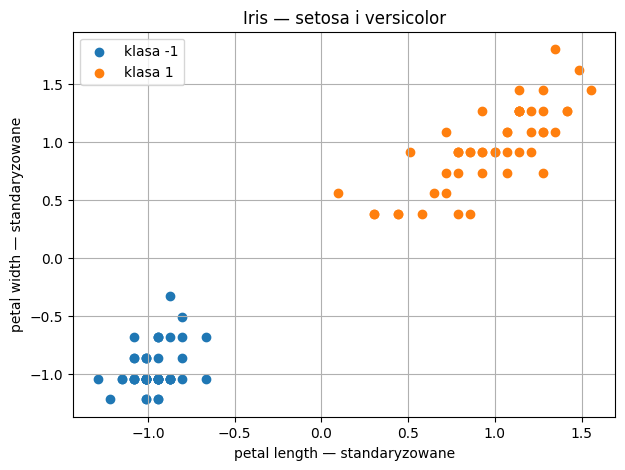

In [12]:

plt.figure(figsize=(7, 5))

for class_id in [-1, 1]:
    mask_class = (
        y_iris == class_id
    )

    plt.scatter(
        X_iris_scaled[
            mask_class,
            0
        ],
        X_iris_scaled[
            mask_class,
            1
        ],
        label=f"klasa {class_id}"
    )

plt.xlabel("petal length — standaryzowane")
plt.ylabel("petal width — standaryzowane")
plt.title("Iris — setosa i versicolor")
plt.legend()
plt.grid()
plt.show()



# 13. Demonstracja własnej implementacji

Sprawdzamy, czy dostępny jest moduł `myHebb.py`.

W repozytorium studenckim gotowego pliku nie musi być.

Student ma przygotować własną implementację o analogicznym interfejsie.


In [13]:

try:
    from myHebb import MyHebbClassifier

    HAS_MY_HEBB = True
    print("Znaleziono implementację.")

except ImportError:
    HAS_MY_HEBB = False
    print("Nie znaleziono implementacji.")


Znaleziono implementację.


w = [96.999  96.0307]
b = 0.0


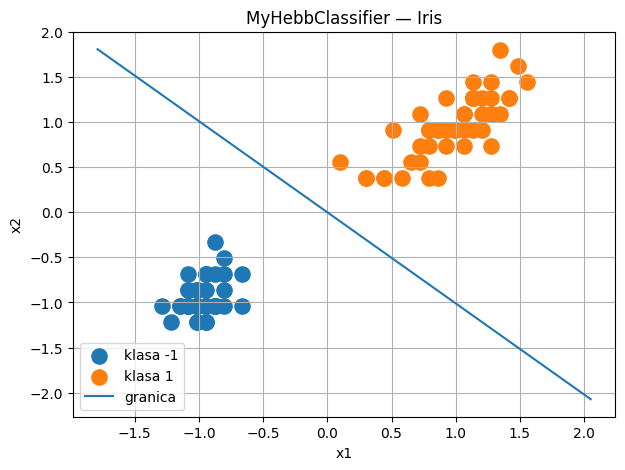

In [14]:

if HAS_MY_HEBB:

    hebb = MyHebbClassifier(
        learning_rate=1.0,
        n_epochs=1
    )

    hebb.fit(
        X_iris_scaled,
        y_iris
    )

    print("w =", hebb.w)
    print("b =", hebb.b)

    plot_linear_boundary(
        X_iris_scaled,
        y_iris,
        hebb.w,
        hebb.b,
        "MyHebbClassifier — Iris"
    )



# 14. Historia wag

Warto przechowywać historię wag po kolejnych aktualizacjach.

Pozwala to zobaczyć, że uczenie nie jest jedną magiczną operacją.

Wagi są modyfikowane **próbka po próbce**.


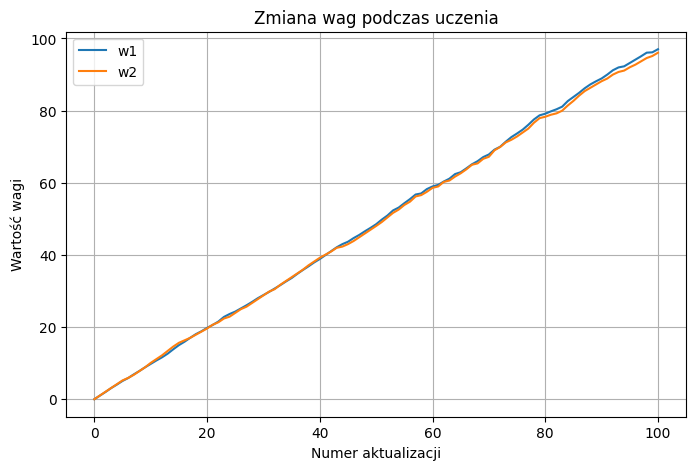

In [15]:

if HAS_MY_HEBB:

    weight_history = np.array(
        hebb.weight_history_
    )

    plt.figure(figsize=(8, 5))

    for feature_index in range(
        weight_history.shape[1]
    ):
        plt.plot(
            weight_history[
                :,
                feature_index
            ],
            label=(
                f"w{feature_index + 1}"
            )
        )

    plt.xlabel("Numer aktualizacji")
    plt.ylabel("Wartość wagi")
    plt.title("Zmiana wag podczas uczenia")
    plt.legend()
    plt.grid()
    plt.show()



# 15. Wpływ skali cech

Reguła:

$$
\Delta \mathbf{w}
=
\eta t\mathbf{x}
$$

bezpośrednio wykorzystuje wartości wejściowe.

Jeżeli jedna cecha ma wartości wielokrotnie większe od pozostałych, jej wkład w zmianę wag może być odpowiednio większy.

Dlatego skala danych może mieć duże znaczenie również tutaj.


In [16]:

X_scale_demo = X_iris.copy()

X_scale_demo[:, 1] *= 100

print("Zakres pierwszej cechy:")
print(
    X_scale_demo[:, 0].min(),
    X_scale_demo[:, 0].max()
)

print("\nZakres drugiej cechy:")
print(
    X_scale_demo[:, 1].min(),
    X_scale_demo[:, 1].max()
)


Zakres pierwszej cechy:
1.0 5.1

Zakres drugiej cechy:
10.0 180.0



### Zastanów się

Jeżeli druga cecha została pomnożona przez `100`, to w aktualizacji:

$$
\eta t\mathbf{x}
$$

jej wkład również może być około `100` razy większy.

Nie oznacza to automatycznie, że jest `100` razy ważniejsza merytorycznie.

To efekt reprezentacji danych.



# 16. Zadanie własne — `MyHebbClassifier`

Przygotuj własny plik:

```text
myHebb.py
```

i zaimplementuj klasę:

```python
class MyHebbClassifier:
    ...
```

## Minimalny interfejs

Klasa powinna posiadać:

```python
fit(X, y)
decision_function(X)
predict(X)
```

oraz atrybuty:

```python
w
b
```

## Wymagania

### `fit(X, y)`

Metoda powinna:

1. przyjmować dane `X`,
2. przyjmować klasy `-1` oraz `1`,
3. zainicjalizować wagi,
4. przechodzić po obserwacjach,
5. zastosować regułę:

$$
\mathbf{w}
\leftarrow
\mathbf{w}
+
\eta t\mathbf{x}
$$

6. aktualizować bias:

$$
b
\leftarrow
b+\eta t
$$

7. umożliwiać wykonanie co najmniej jednej epoki.

### `decision_function(X)`

Powinna zwracać:

$$
\mathbf{w}^T\mathbf{x}+b
$$

### `predict(X)`

Powinna zwracać:

$$
-1
$$

lub:

$$
1
$$

na podstawie znaku funkcji decyzyjnej.

## Dodatkowo

Warto zapisywać historię wag po kolejnych aktualizacjach.

Pozwoli to później zwizualizować proces uczenia.

> Nie używamy gotowego modelu z biblioteki jako implementacji zadania.



# 17. Testy własnej implementacji

Sprawdź klasę najpierw na:

1. AND,
2. OR,
3. XOR.

Następnie sprawdź ją na dwóch klasach Iris.

### Odpowiedz

- Dlaczego AND może zostać rozdzielone liniowo?
- Dlaczego OR może zostać rozdzielone liniowo?
- Dlaczego XOR nie może?
- Czy zwiększenie liczby epok rozwiązuje problem XOR?
- Co dzieje się z wagami po wielu epokach?
- Dlaczego kodowanie bipolarne jest wygodne?
- Dlaczego skala cech wpływa na aktualizacje wag?



# 18. Pytania podsumowujące

1. Jaka jest podstawowa idea reguły Hebba?
2. Jak wygląda podstawowa reguła zmiany wagi?
3. Co oznacza współczynnik `eta`?
4. Kiedy waga rośnie?
5. Kiedy waga maleje?
6. Jak zapisujemy regułę Hebba w postaci wektorowej?
7. Jak wygląda nadzorowana wersja używana na zajęciach?
8. Po co stosujemy kodowanie `-1 / 1`?
9. Jaką rolę pełni bias?
10. Jak działa funkcja decyzyjna?
11. Dlaczego AND jest liniowo separowalne?
12. Dlaczego XOR nie jest liniowo separowalne?
13. Dlaczego większa liczba epok nie rozwiąże problemu XOR?
14. Czy podstawowa reguła Hebba aktualizuje wagi tylko po błędzie?
15. Dlaczego wagi mogą rosnąć przy kolejnych epokach?
16. Dlaczego skala cech ma znaczenie?
17. Czym własna implementacja Hebba różni się od gotowego klasyfikatora z biblioteki?



# 19. Najważniejsze wnioski

> **Reguła Hebba wzmacnia lub osłabia połączenia na podstawie współwystępowania sygnałów.**

> **W nadzorowanej wersji stosowanej na zajęciach aktualizacja zależy od wejścia i wartości docelowej.**

> **Prosty neuron Hebba tworzy liniową granicę decyzyjną.**

> **Dlatego może rozwiązać AND i OR, ale nie XOR.**

> **Klasyczna reguła Hebba nie jest mechanizmem korekcji błędu — aktualizacja nie zależy od tego, czy aktualna predykcja była poprawna.**

Na kolejnych zajęciach wykorzystamy regułę Hebba do **sieci Hopfielda i pamięci asocjacyjnej**.
